In [208]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from helper_functions import plot_predictions
import matplotlib.pyplot as plt
import numpy as np

In [209]:
N_CIRCLES = 1000
X,y = make_circles(N_CIRCLES, shuffle=True, noise = 0.02, random_state=67)

In [210]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

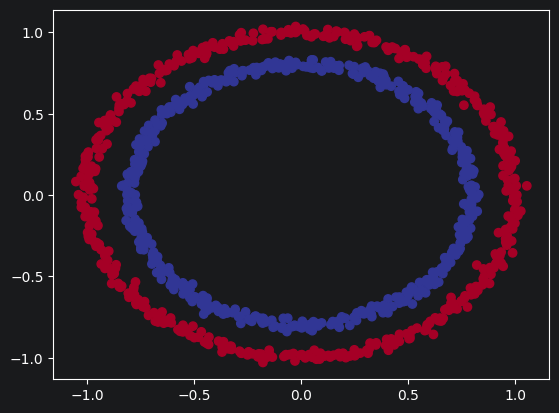

In [211]:
plt.scatter(x = X[:,0],
            y = X[:,1],
            c = y,
            cmap = plt.cm.RdYlBu)

In [212]:
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

In [213]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=67)

In [214]:
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_0 = nn.Linear(2,10)
        self.linear_1 = nn.Linear(10,10)
        self.linear_2 = nn.Linear(10,1)
        self.relu = nn.ReLU()

    def forward(self, X:torch.Tensor):
        y = self.linear_2(self.relu(self.linear_1(self.relu(self.linear_0(X)))))
        return y

In [215]:
torch.manual_seed(42)
model = CircleModelV0().to(device)

In [216]:
with torch.inference_mode():
    y_initial_logits = model(X)
    y_initial_probs = torch.sigmoid(y_initial_logits)
    y_initial_preds = torch.round(y_initial_probs)
y_initial_logits

tensor([[0.0263],
        [0.0505],
        [0.0138],
        [0.0399],
        [0.0253],
        [0.0300],
        [0.0216],
        [0.0436],
        [0.0256],
        [0.0497],
        [0.0162],
        [0.0140],
        [0.0075],
        [0.0176],
        [0.0205],
        [0.0161],
        [0.0239],
        [0.0327],
        [0.0081],
        [0.0078],
        [0.0079],
        [0.0213],
        [0.0143],
        [0.0128],
        [0.0295],
        [0.0216],
        [0.0212],
        [0.0296],
        [0.0219],
        [0.0228],
        [0.0209],
        [0.0217],
        [0.0285],
        [0.0189],
        [0.0126],
        [0.0055],
        [0.0216],
        [0.0188],
        [0.0175],
        [0.0078],
        [0.0202],
        [0.0267],
        [0.0414],
        [0.0205],
        [0.0300],
        [0.0521],
        [0.0313],
        [0.0381],
        [0.0282],
        [0.0091],
        [0.0167],
        [0.0111],
        [0.0095],
        [0.0068],
        [0.0211],
        [0

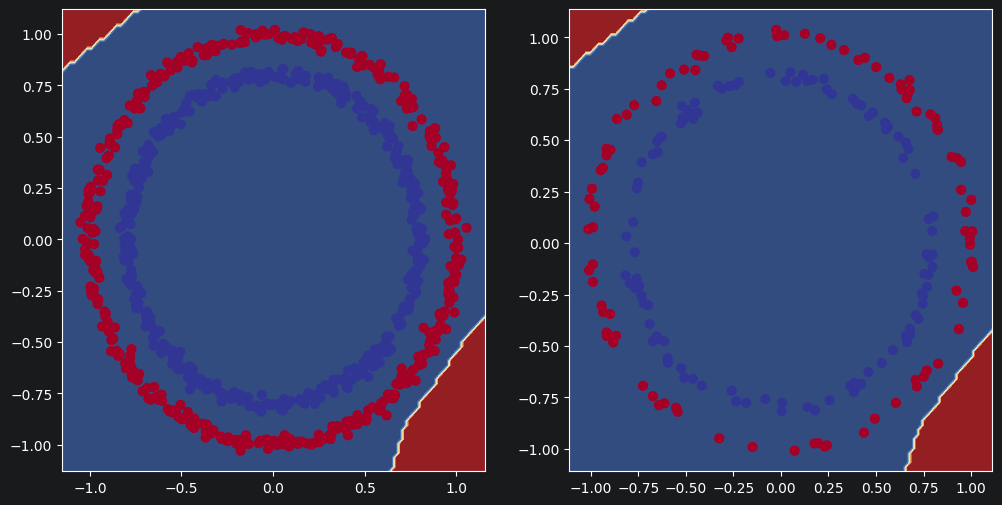

In [217]:
from helper_functions import plot_decision_boundary
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plot_decision_boundary(model,X_train,y_train)

plt.subplot(1,2,2)
plot_decision_boundary(model, X_test,y_test)

In [218]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(lr = 0.1, params=model.parameters())

In [219]:
def accuracy_fn(y_true, y_labels):
    correct = torch.eq(y_true, y_labels).sum().item()
    acc = correct/len(y_true) * 100
    return acc

In [220]:
epochs = 100000

epoch_count = []
loss_values = []
test_loss_values = []

for epoch in range(epochs):
    model.train()

    y_logits = model(X_train.unsqueeze(1))
    y_probs = torch.sigmoid(y_logits)
    y_preds = torch.round(y_probs)

    loss = loss_fn(y_logits.squeeze(), y_train.squeeze())
    accuracy = accuracy_fn(y_train.squeeze(), y_preds.squeeze())

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


    model.eval()
    with torch.inference_mode():
        y_test_logits = model(X_test.unsqueeze(1))
        y_test_probs = torch.sigmoid(y_test_logits)
        y_test_preds = torch.round(y_test_probs)

        test_loss = loss_fn(y_test_logits.squeeze(), y_test)
        test_accuracy = accuracy_fn(y_test.squeeze(), y_test_preds.squeeze())

    if epoch % 500 == 0:
        epoch_count.append(epoch)
        loss_values.append(loss)
        test_loss_values.append(test_loss)
        print(f"Epoch : {epoch} ! Loss : {loss} ! Acc : {accuracy} ! Test Loss {test_loss} ! Test Acc {test_accuracy}")

Epoch : 0 ! Loss : 0.6930882334709167 ! Acc : 49.5 ! Test Loss 0.6923888921737671 ! Test Acc 52.0
Epoch : 500 ! Loss : 0.6799288988113403 ! Acc : 53.75 ! Test Loss 0.6806699633598328 ! Test Acc 53.5
Epoch : 1000 ! Loss : 0.5624203681945801 ! Acc : 86.25 ! Test Loss 0.5632390379905701 ! Test Acc 83.5
Epoch : 1500 ! Loss : 0.10642839223146439 ! Acc : 99.875 ! Test Loss 0.10648304969072342 ! Test Acc 100.0
Epoch : 2000 ! Loss : 0.033183153718709946 ! Acc : 100.0 ! Test Loss 0.03952225297689438 ! Test Acc 100.0
Epoch : 2500 ! Loss : 0.018557658419013023 ! Acc : 100.0 ! Test Loss 0.024901967495679855 ! Test Acc 100.0
Epoch : 3000 ! Loss : 0.012744331732392311 ! Acc : 100.0 ! Test Loss 0.01838313788175583 ! Test Acc 100.0
Epoch : 3500 ! Loss : 0.009705197997391224 ! Acc : 100.0 ! Test Loss 0.014831590466201305 ! Test Acc 100.0
Epoch : 4000 ! Loss : 0.007850618101656437 ! Acc : 100.0 ! Test Loss 0.01238891202956438 ! Test Acc 100.0
Epoch : 4500 ! Loss : 0.006602410692721605 ! Acc : 100.0 ! Te

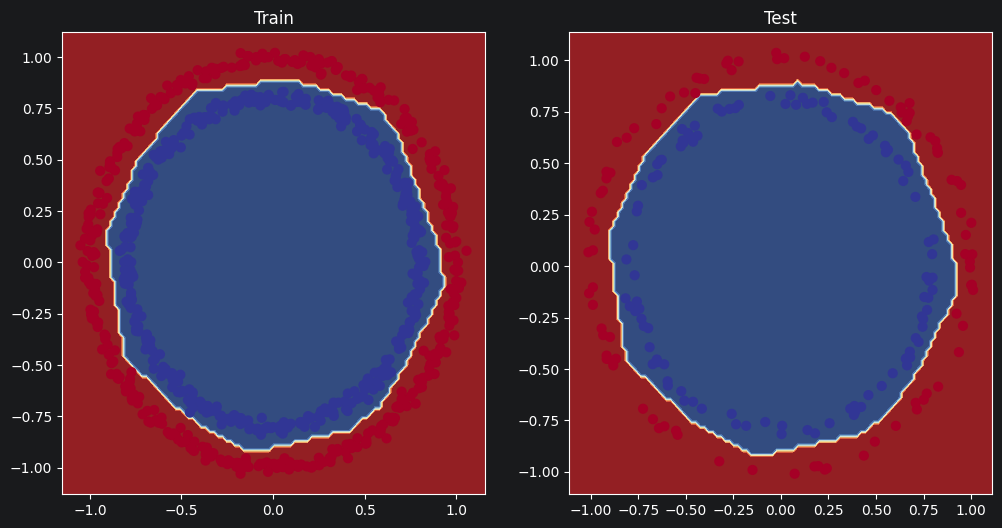

In [221]:
from helper_functions import plot_loss_curves
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model, X_train, y_train)

plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model, X_test, y_test)

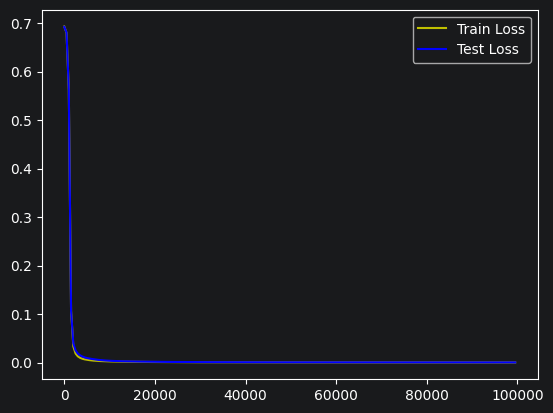

In [229]:
plt.figure()
plt.plot(epoch_count, np.array(torch.tensor(loss_values).numpy()), c = "y", label = "Train Loss")
plt.plot(epoch_count, np.array(torch.tensor(test_loss_values).numpy()), c = "b", label =  "Test Loss")
plt.legend()